In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset and chek the info and description of the data

df = pd.read_csv("energy_efficiency_data.csv", sep=",")
df.info()
df.describe(include="all")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Relative_Compactness       768 non-null    float64
 1   Surface_Area               768 non-null    float64
 2   Wall_Area                  768 non-null    float64
 3   Roof_Area                  768 non-null    float64
 4   Overall_Height             768 non-null    float64
 5   Orientation                768 non-null    int64  
 6   Glazing_Area               768 non-null    float64
 7   Glazing_Area_Distribution  768 non-null    int64  
 8   Heating_Load               768 non-null    float64
 9   Cooling_Load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307201,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090196,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


In [5]:
# Check for missing values

df.isna().sum()

Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
Cooling_Load                 0
dtype: int64

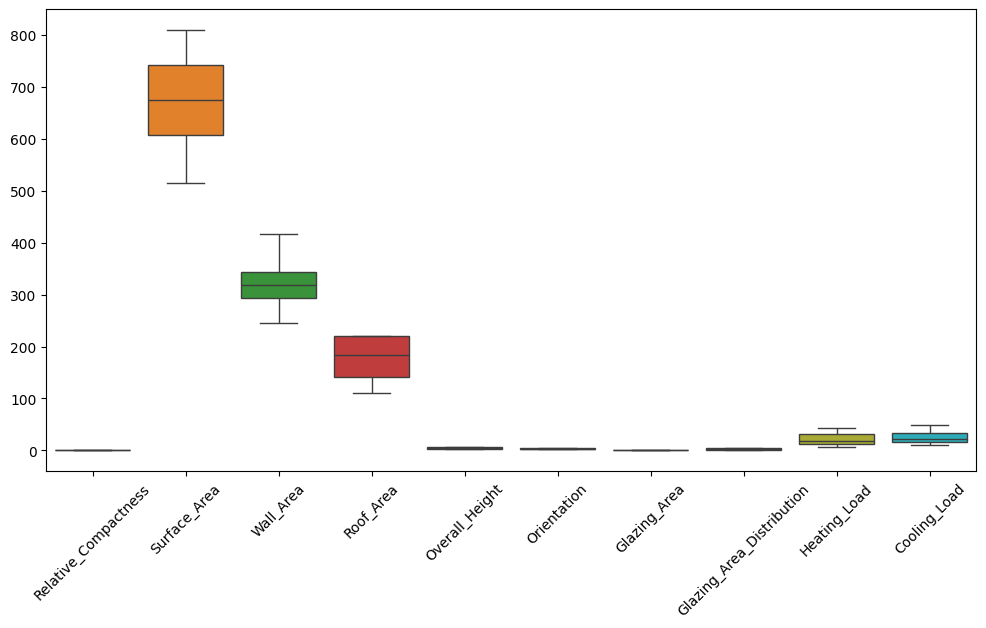

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# Visualiser la distribution des données

plt.figure(figsize=(12,6))
sns.boxplot(data=df)
plt.xticks(rotation=45)
plt.show()


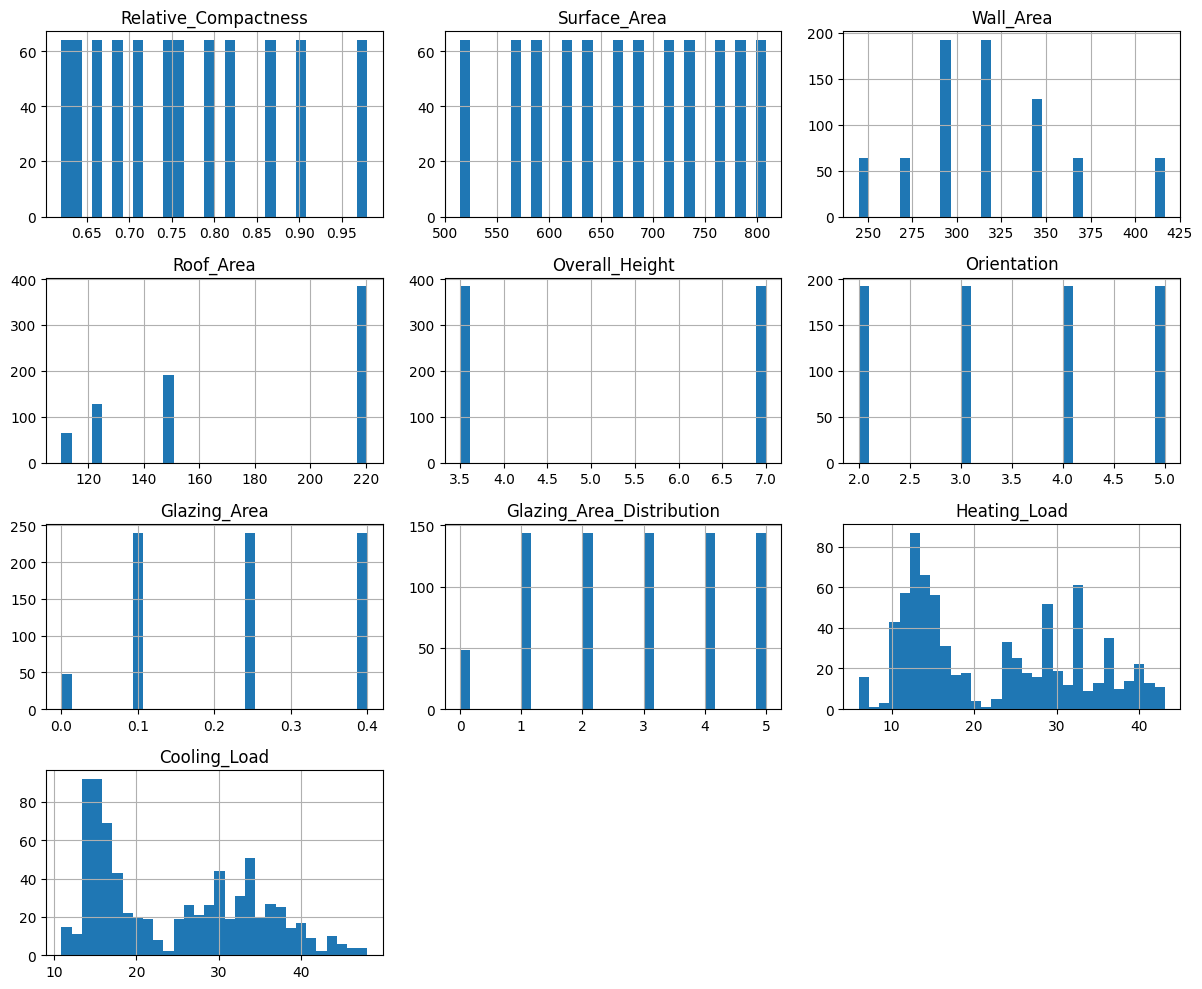

In [7]:
# Tracer les histogrammes des données

df.hist(figsize=(12,10), bins=30)
plt.tight_layout()
plt.show()


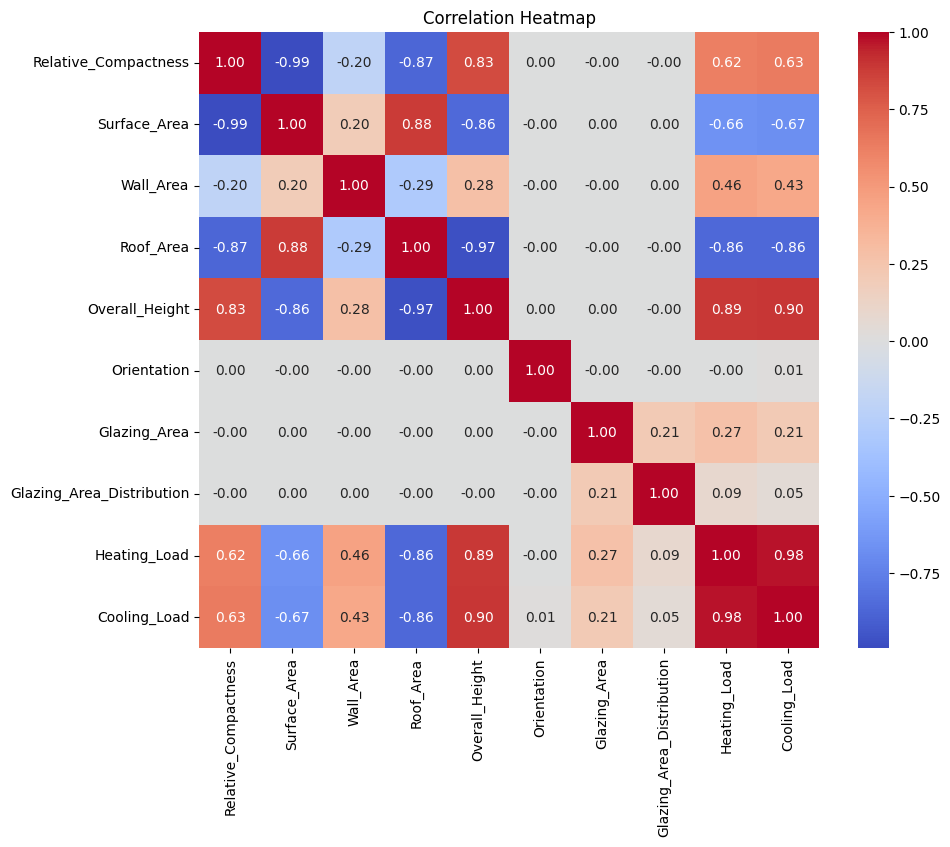

In [8]:
# Calculer et visualiser la matrice de corrélation

corr = df.corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# Preparation des données pour l'entrainement du modèle
# Normalisation Z-score des variables X et y

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(["Heating_Load", "Cooling_Load"], axis=1)
y = df[["Heating_Load", "Cooling_Load"]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test  = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train = scaler_y.fit_transform(y_train)
y_test  = scaler_y.transform(y_test)





In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

X_train2, X_val, y_train2, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42
)

X_train_tensor = torch.tensor(X_train2, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train2, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=32, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test_tensor, y_test_tensor), batch_size=64, shuffle=False)
val_loader = DataLoader(TensorDataset(X_val_tensor, y_val_tensor), batch_size=64, shuffle=False)

print(X_train_tensor.shape, y_train_tensor.shape) 



torch.Size([521, 8]) torch.Size([521, 2])


In [12]:
class MLPregression(nn.Module):
    def __init__(self, input_dim=8, dropout=0.1):
        super(MLPregression, self).__init__()
        self.fc1 = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.fc2 = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.fc3 = nn.Linear(32, 2)

    def forward(self, x):
        x = self.fc1(x)
        x = self.fc2(x)
        x = self.fc3(x)
        return x
    
model = MLPregression()

print(model)

MLPregression(
  (fc1): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
  )
  (fc2): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
  )
  (fc3): Linear(in_features=32, out_features=2, bias=True)
)


In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)


In [14]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss = 0.0

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            pred = model(xb)
            loss = criterion(pred, yb)

            if train:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * xb.size(0)

    return total_loss / len(loader.dataset)


best_val = float("inf")
patience, wait = 20, 0
best_state = None

train_losses, val_losses = [], []

for epoch in range(1, 501):  # max epochs, early stopping va couper avant
    train_loss = run_epoch(train_loader, train=True)
    val_loss   = run_epoch(val_loader, train=False)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val - 1e-6:
        best_val = val_loss
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            break



model.load_state_dict(best_state)


<All keys matched successfully>

In [23]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model.eval()
preds, trues = [], []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        pred = model(xb).cpu().numpy()
        preds.append(pred)
        trues.append(yb.numpy())

y_pred = np.vstack(preds)
y_true = np.vstack(trues)

# métriques par sortie
for i, name in enumerate(["Heating_Load", "Cooling_Load"]):
    mae  = mean_absolute_error(y_true[:, i], y_pred[:, i])
    rmse = np.sqrt(mean_squared_error(y_true[:, i], y_pred[:, i]))
    r2   = r2_score(y_true[:, i], y_pred[:, i])
    print(name, "MAE=", mae, "RMSE=", rmse, "R2=", r2)


Heating_Load MAE= 0.05908096581697464 RMSE= 0.07827198387743366 R2= 0.994067907333374
Cooling_Load MAE= 0.10563332587480545 RMSE= 0.1462813750973244 R2= 0.9792941808700562


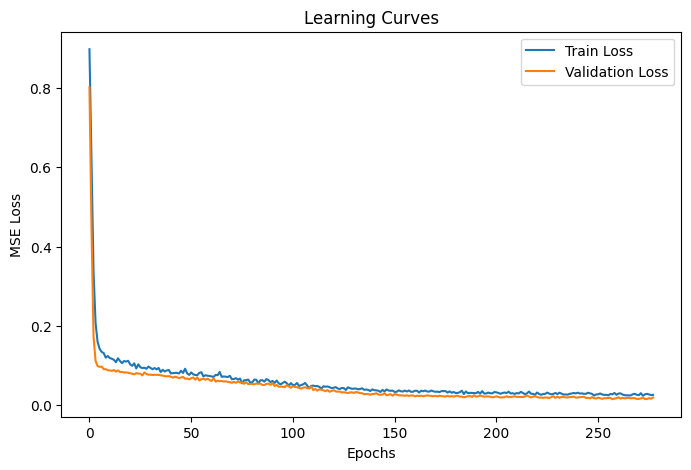

In [24]:
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.title("Learning Curves")
plt.show()



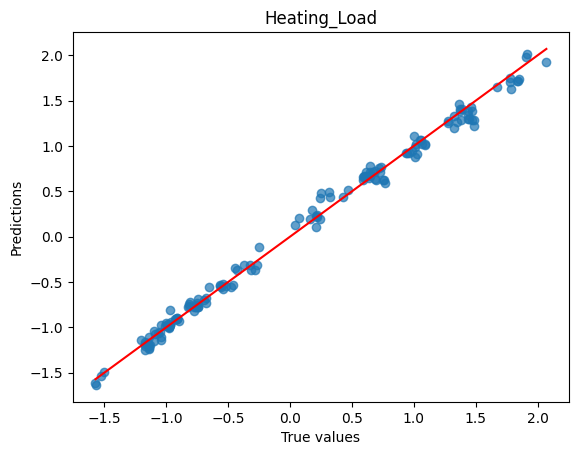

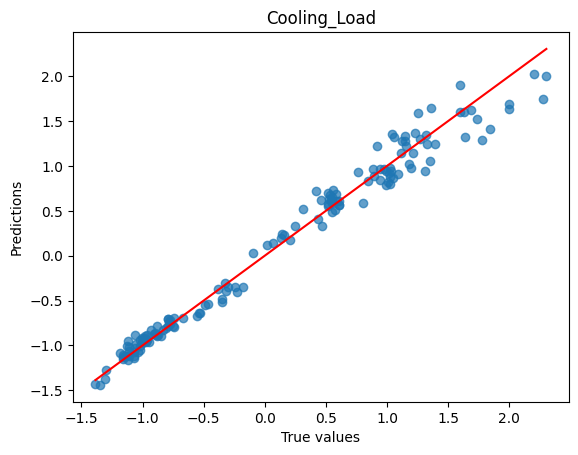

In [25]:
for i, name in enumerate(["Heating_Load", "Cooling_Load"]):
    plt.figure()
    plt.scatter(y_true[:, i], y_pred[:, i], alpha=0.7)
    plt.plot([y_true[:, i].min(), y_true[:, i].max()],
             [y_true[:, i].min(), y_true[:, i].max()], 'r')
    plt.xlabel("True values")
    plt.ylabel("Predictions")
    plt.title(name)
    plt.show()



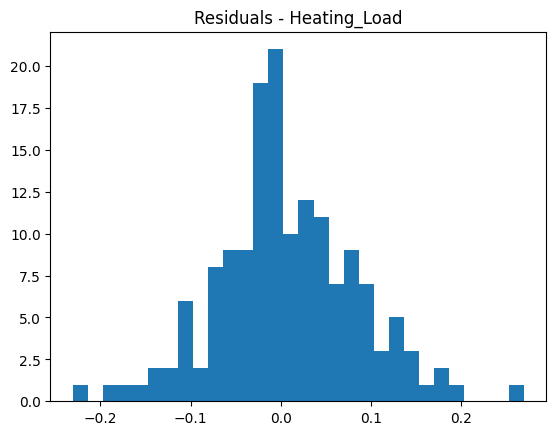

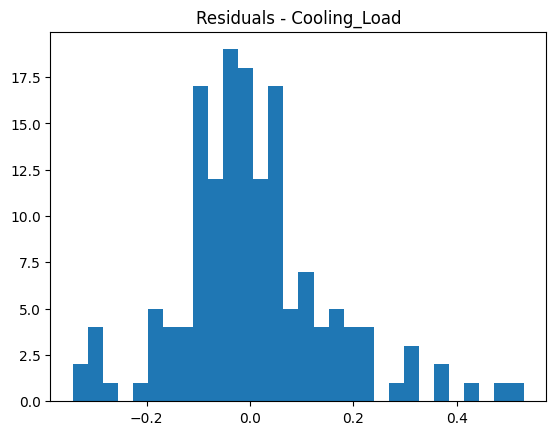

In [26]:
errors = y_true - y_pred

for i, name in enumerate(["Heating_Load", "Cooling_Load"]):
    plt.figure()
    plt.hist(errors[:, i], bins=30)
    plt.title(f"Residuals - {name}")
    plt.show()
